# **Customer Churn Analysis**

**Author:** Md Sajid Ansari  |  **Project type:** Exploratory data analysis and KPI design (individual, practice dataset)
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn), SQL, SQLite
**GitHub:** github.com/ansarisajid064-arch/customer-churn-analysis

---

## Project Summary

This project studies why subscription customers cancel. Customer, subscription and support data are read from a SQLite database with SQL, cleaned, joined into one analysis-ready table, and used to build churn KPIs and charts.

**What the notebook does**

1. Reads three tables (`db_customer`, `db_subscription`, `db_support`) from SQLite with SQL.
2. Cleans the data: renames and drops columns, fixes data types, standardizes labels and fills missing values.
3. Engineers features: churn flag, customer tenure, complaint count, escalation flag and churn-risk segments.
4. Calculates KPIs: churn rate, retention rate, ARPU, average tenure, revenue lost to churn, escalation rate and complaints per customer.
5. Breaks churn down by plan, subscription channel, state and month, and tests how escalations relate to churn.

> **Important limitation:** the dataset is very small (21 customers, 6 churned). Every number here shows the *method* working end to end. None of it is statistically strong enough to generalize. Each section says where this matters.

## Problem Statement and Business Objective

A subscription business is losing customers and wants to know **who is leaving, why, and where to act first**.

**Objectives**

1. Measure overall churn and retention.
2. Find which plans, acquisition channels and states have the highest churn.
3. Understand whether support escalations are linked to churn.
4. Segment customers by churn risk so retention effort can be prioritized.
5. Quantify the revenue impact of churn.

## Data Dictionary

| Table | Key columns used |
|---|---|
| `db_customer` | `customerid`, `name`, `country`, `state`, `gender`, `dob` (also `interests`, `pincode`: mostly empty, dropped) |
| `db_subscription` | `customerid`, `subscription_start_date`, `subscription_type`, `renewal_date`, `plan_type`, `contract_type`, `cancellation_date`, `cancellation_reason`, `monthly_charges`, `cltv`, `churn_score` |
| `db_support` | `customerid`, `complaint_date`, `escalations` (Y/N), `csat_score` (also `col_1`: empty, `comment`: free text, both dropped) |

**Grain:** one row per customer in the subscription table. Support has several complaints per customer for some customers, so it is reduced to one row per customer before joining.

## 1. Setup and Data Loading

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

# Database in the same folder as this notebook, or set the full path, e.g.
# DB_PATH = Path(r'C:\Users\ansar\Documents\churn\customer_churn.db')
DB_PATH = Path('customer_churn.db').resolve()

### Load the three tables with SQL

In [2]:
if not DB_PATH.exists() or DB_PATH.stat().st_size == 0:
    raise FileNotFoundError(
        f'No usable database at {DB_PATH}. '
        'Put customer_churn.db next to this notebook or set DB_PATH to its full path.'
    )

# Read-only: SQLite raises an error instead of silently creating an empty file
with closing(sqlite3.connect(f'{DB_PATH.as_uri()}?mode=ro', uri=True)) as conn:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist()
    print('Tables found:', tables)

    for t in tables:
        cols = pd.read_sql(f'PRAGMA table_info({t});', conn)['name'].tolist()
        print(f'  {t}: {cols}')

    customers     = pd.read_sql('SELECT * FROM db_customer', conn)
    subscriptions = pd.read_sql('SELECT * FROM db_subscription', conn)
    support       = pd.read_sql('SELECT * FROM db_support', conn)

for name, frame in [('customers', customers), ('subscriptions', subscriptions), ('support', support)]:
    print(f'{name:14s} rows={frame.shape[0]:3d}  cols={frame.shape[1]:2d}  unique customers={frame["customerid"].nunique()}')

Tables found: ['db_customer', 'db_subscription', 'db_support']
  db_customer: ['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']
  db_subscription: ['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']
  db_support: ['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']
customers      rows= 21  cols= 8  unique customers=21
subscriptions  rows= 21  cols=11  unique customers=21
support        rows=  9  cols= 6  unique customers=7


**What the data tells us:** `customers` and `subscriptions` cover the same customers, but `support` has fewer unique customers than rows. Some customers raised several complaints, so it needs de-duplicating before the join, otherwise the join would duplicate customers and distort every KPI.

## 2. Data Cleaning

Planned fixes:

| # | Table | Fix | Reason |
|---|---|---|---|
| a | customers | Drop `interests`, `pincode` | Almost entirely empty |
| b | customers | Rename `name` to `customer_name` | Clearer column name |
| c | customers | Convert `dob` to datetime | Stored as text |
| d | customers | Standardize `gender` (`Men`/`Women` to `Male`/`Female`) | Inconsistent labels |
| e | customers | Fill missing `country` from `state` | Same state always maps to the same country |
| f | subscriptions | Convert date columns to datetime | Stored as text |
| g | subscriptions | Fix spelling `Refferal` to `Referral` | Typo in the source labels |
| h | support | Drop `col_1`, `comment`; convert `complaint_date` | Empty column, free text not analysed |

### Customers

In [3]:
customers = customers.rename(columns={'name': 'customer_name'})
customers = customers.drop(columns=['interests', 'pincode'])
customers['dob'] = pd.to_datetime(customers['dob'])
customers['gender'] = customers['gender'].replace({'Men': 'Male', 'Women': 'Female'})

# Fill missing country using the state -> country pairs that are known
state_to_country = (customers.dropna(subset=['country'])
                             .drop_duplicates('state')
                             .set_index('state')['country'])
customers['country'] = customers['country'].fillna(customers['state'].map(state_to_country))

print('Missing values after cleaning:')
print(customers.isna().sum())

Missing values after cleaning:
customerid       0
customer_name    0
country          0
state            0
gender           0
dob              0
dtype: int64


Any country still missing here would belong to a state that has no country recorded for any customer, so it cannot be inferred from the data and would need a business decision.

### Subscriptions

In [4]:
date_cols = ['subscription_start_date', 'renewal_date', 'cancellation_date']
subscriptions[date_cols] = subscriptions[date_cols].apply(pd.to_datetime)
subscriptions['subscription_type'] = subscriptions['subscription_type'].replace({'Refferal': 'Referral'})

subscriptions.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


### Support

In [5]:
support = support.drop(columns=['col_1', 'comment'])
support['complaint_date'] = pd.to_datetime(support['complaint_date'])
support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


## 3. Feature Engineering and Joining

### 3.1 Churn flag
A customer has churned if they have a cancellation date.

In [6]:
subscriptions['churn_flag'] = np.where(subscriptions['cancellation_date'].notna(), 1, 0)
subscriptions[['customerid', 'cancellation_date', 'churn_flag']].head()

,customerid,cancellation_date,churn_flag
0,0002-ORFBO,NaT,0
1,0003-MKNFE,2024-09-10,1
2,0004-TLHLJ,NaT,0
3,0011-IGKFF,NaT,0
4,0013-EXCHZ,2024-02-28,1


### 3.2 Support: complaint count, then one row per customer
Count each customer's complaints first, then keep only their **most recent** complaint (so its `escalations` and `csat_score` values describe the latest interaction).

> **Limitation:** if a customer escalated an earlier complaint but not the latest one, that escalation is not captured by this approach.

In [7]:
support['complaint_count'] = support.groupby('customerid')['customerid'].transform('count')
support = support.sort_values('complaint_date').drop_duplicates('customerid', keep='last')

print('Support rows after de-duplication:', len(support), '| unique customers:', support['customerid'].nunique())

Support rows after de-duplication: 7 | unique customers: 7


### 3.3 Join into one analysis table
The subscription table drives the join (`how='left'`), so every customer stays, with or without support history. A check confirms the joins did not duplicate any customer.

In [8]:
df = (subscriptions
      .merge(customers, on='customerid', how='left')
      .merge(support,   on='customerid', how='left'))

assert df['customerid'].is_unique, 'Join created duplicate customers'
print('Analysis table shape:', df.shape)
df.head()

Analysis table shape: (21, 21)


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Referral,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Referral,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0


### 3.4 Derived columns

| Column | Definition |
|---|---|
| `tenure_days` | Days from subscription start to cancellation, or to today for active customers |
| `complaint_count` | Number of complaints; customers with no support record get 0 |
| `escalated` | 1 if the latest complaint was escalated (`Y`), otherwise 0. Customers with no complaint are treated as 0 |
| `churn_risk` | From the supplied `churn_score`: `low` (< 50), `med` (50 to 69), `high` (70 and above) |
| `cancellation_month` | Month of cancellation, used for the trend chart |

> `tenure_days` for active customers depends on the date you run the notebook, so the average tenure will drift upward over time.

In [9]:
as_of = pd.Timestamp.today().normalize()
print('Tenure measured up to:', as_of.date())

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (as_of - df['subscription_start_date']).dt.days,
)

df['complaint_count'] = df['complaint_count'].fillna(0).astype(int)
df['escalated'] = (df['escalations'] == 'Y').astype(int)

df['churn_risk'] = np.select(
    [df['churn_score'] < 50, df['churn_score'] < 70],
    ['low', 'med'],
    default='high',
)

df['cancellation_month'] = df['cancellation_date'].dt.to_period('M')

df[['customerid', 'churn_flag', 'tenure_days', 'complaint_count', 'escalated', 'churn_score', 'churn_risk']].head(8)

Tenure measured up to: 2026-10-15


,customerid,churn_flag,tenure_days,complaint_count,escalated,churn_score,churn_risk
0,0002-ORFBO,0,2040.0,0,0,12,low
1,0003-MKNFE,1,1501.0,2,1,91,high
2,0004-TLHLJ,0,1425.0,0,0,34,low
3,0011-IGKFF,0,2715.0,0,0,8,low
4,0013-EXCHZ,1,419.0,1,1,88,high
5,0013-MHZWF,0,1580.0,1,0,22,low
6,0013-SMEOE,1,1142.0,1,0,79,high
7,0014-BMAQU,0,2435.0,0,0,5,low


In [10]:
df.to_csv('exported_churn_data.csv', index=False)
print('Exported', len(df), 'rows to exported_churn_data.csv')

Exported 21 rows to exported_churn_data.csv


## 4. KPI Calculation

| KPI | Definition |
|---|---|
| Churn rate | Churned customers / all customers |
| Retention rate | 100 minus churn rate |
| ARPU | Average `monthly_charges` per customer |
| Average tenure | Mean `tenure_days` |
| Revenue at risk | Sum of `monthly_charges` for customers who churned (the monthly revenue already lost). The currency unit is not given in the source data |
| Escalation rate | Share of customers whose latest complaint was escalated, shown both across all customers and across only those who complained |
| Complaints per customer | Total complaints / total customers |

In [11]:
churn_rate     = df['churn_flag'].mean() * 100
retention_rate = 100 - churn_rate
arpu           = df['monthly_charges'].mean()
avg_tenure     = df['tenure_days'].mean()
revenue_at_risk = df.loc[df['churn_flag'] == 1, 'monthly_charges'].sum()

esc_rate_all     = df['escalated'].mean() * 100
esc_rate_callers = df.loc[df['complaint_count'] > 0, 'escalated'].mean() * 100
complaints_per_customer = df['complaint_count'].sum() / df['customerid'].nunique()

kpis = pd.Series({
    'Customers': len(df),
    'Churned customers': int(df['churn_flag'].sum()),
    'Churn rate (%)': round(churn_rate, 2),
    'Retention rate (%)': round(retention_rate, 2),
    'ARPU': round(arpu, 2),
    'Average tenure (days)': round(avg_tenure, 0),
    'Revenue at risk (churned monthly charges)': round(revenue_at_risk, 2),
    'Escalation rate, all customers (%)': round(esc_rate_all, 2),
    'Escalation rate, customers who complained (%)': round(esc_rate_callers, 2),
    'Complaints per customer': round(complaints_per_customer, 2),
}, name='Value')
kpis.to_frame()

,Value
Customers,21.00
Churned customers,6.00
Churn rate (%),28.57
Retention rate (%),71.43
ARPU,18.85
Average tenure (days),1561.00
Revenue at risk (churned monthly charges),73.94
"Escalation rate, all customers (%)",19.05
"Escalation rate, customers who complained (%)",57.14
Complaints per customer,0.43


### Why do customers cancel?
Churn rate says *how many* leave; cancellation reasons say *why*, which decides the right retention action.

In [12]:
reasons = df.loc[df['churn_flag'] == 1, 'cancellation_reason'].value_counts()
reasons.to_frame('churned customers')

,churned customers
cancellation_reason,
Switched to competitor,2
Too expensive,1
Not enough content,1
Poor streaming quality,1
Forgot to cancel trial,1


### Revenue exposed among customers still active

In [13]:
at_risk_active = df[(df['churn_flag'] == 0) & (df['churn_risk'] == 'high')]
print('Active customers flagged high risk:', len(at_risk_active))
print('Their monthly charges:', round(at_risk_active['monthly_charges'].sum(), 2))
at_risk_active[['customerid', 'plan_type', 'contract_type', 'monthly_charges', 'churn_score']]

Active customers flagged high risk: 0
Their monthly charges: 0.0


,customerid,plan_type,contract_type,monthly_charges,churn_score


## 5. Visualization and Insights

Each chart below answers a question, with a note on why the chart type was chosen, what it shows, and what a business could do with it.

### Chart 1: Churn rate by plan type

,customers,churned,churn_rate_pct
plan_type,,,
Basic,5,3,60.00
Standard,9,2,22.22
Premium,7,1,14.29


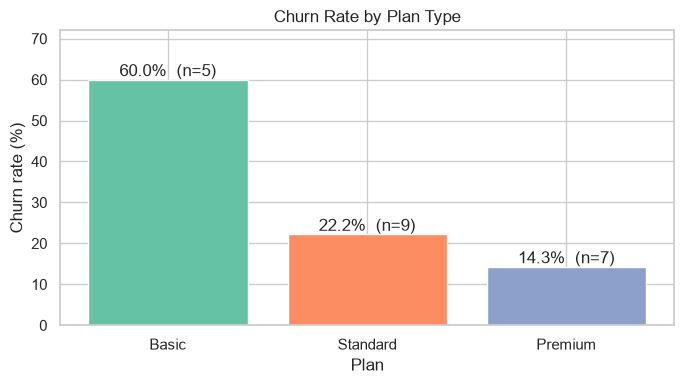

In [14]:
plan_order = ['Basic', 'Standard', 'Premium']
by_plan = (df.groupby('plan_type')
             .agg(customers=('customerid', 'count'),
                  churned=('churn_flag', 'sum'),
                  churn_rate_pct=('churn_flag', lambda s: round(s.mean() * 100, 2)))
             .reindex(plan_order))
display(by_plan)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(by_plan.index, by_plan['churn_rate_pct'], color=sns.color_palette('Set2', len(by_plan)))
ax.bar_label(bars, labels=[f"{v:.1f}%  (n={n})" for v, n in zip(by_plan['churn_rate_pct'], by_plan['customers'])])
ax.set_title('Churn Rate by Plan Type')
ax.set_xlabel('Plan')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, by_plan['churn_rate_pct'].max() * 1.2)
plt.tight_layout()
plt.show()

**Why this chart?** A bar chart compares a rate across a few ordered categories. Labelling each bar with the customer count keeps the small sample sizes visible.

**Insight:** Churn falls as the plan tier rises. In this dataset, Basic churns at 60% (3 of 5 customers), Standard at about 22% (2 of 9) and Premium at about 14% (1 of 7).

**Business impact:** The cheapest plan loses customers fastest, so an upgrade offer or onboarding support aimed at Basic users is the first thing to test. The counts are small, so this is a lead to verify, not a proven pattern.

### Chart 2: Churn rate by subscription (acquisition) type

,customers,churned,churn_rate_pct,total_monthly_revenue
subscription_type,,,,
Referral,6,5,83.33,74.94
Paid,6,1,16.67,174.94
Organic,9,0,0.00,145.91


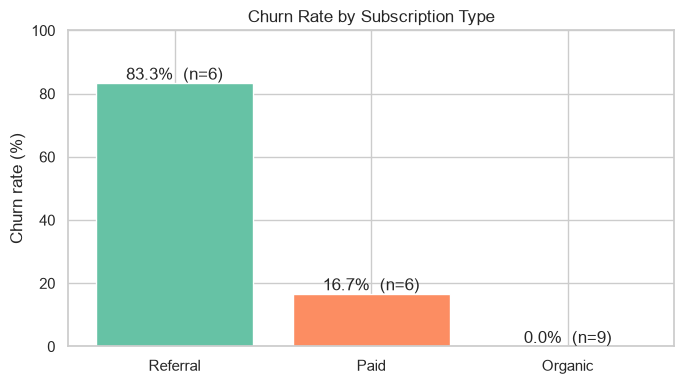

In [15]:
by_type = (df.groupby('subscription_type')
             .agg(customers=('customerid', 'count'),
                  churned=('churn_flag', 'sum'),
                  churn_rate_pct=('churn_flag', lambda s: round(s.mean() * 100, 2)),
                  total_monthly_revenue=('monthly_charges', 'sum'))
             .sort_values('churn_rate_pct', ascending=False))
display(by_type)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(by_type.index, by_type['churn_rate_pct'], color=sns.color_palette('Set2', len(by_type)))
ax.bar_label(bars, labels=[f"{v:.1f}%  (n={n})" for v, n in zip(by_type['churn_rate_pct'], by_type['customers'])])
ax.set_title('Churn Rate by Subscription Type')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**Why this chart?** Same reasoning as Chart 1: a rate compared across a few categories, sorted from highest to lowest.

**Insight:** Referral customers churn far more than the other channels (5 of 6 cancelled, about 83%). Organic customers show no churn (0 of 9) and Paid customers about 17% (1 of 6).

**Business impact:** If this holds on real data, the referral channel brings in customers who do not stay, which makes it worth checking whether referral incentives attract the wrong customers. Compare it with the cancellation reasons above before acting.

### Chart 3: Churn rate by state

,customers,churned,churn_rate_pct,total_monthly_revenue
state,,,,
Karnataka,2,2,100.00,20.98
Meghalaya,3,2,66.67,42.97
Telangana,2,1,50.00,30.98
Delhi,4,1,25.00,52.96
Kathmandu,2,0,0.00,20.98
Maharashtra,3,0,0.00,50.97
Nagaland,1,0,0.00,22.99
Rajasthan,2,0,0.00,36.98
Uttar Pradesh,2,0,0.00,115.98


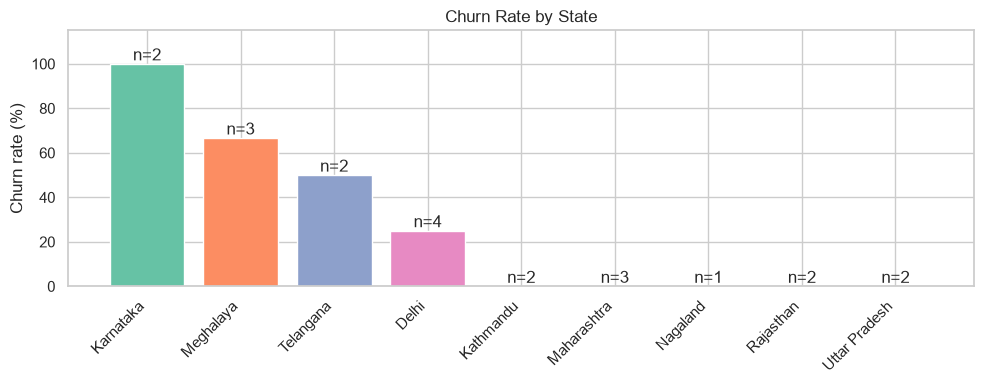

In [16]:
by_state = (df.groupby('state')
              .agg(customers=('customerid', 'count'),
                   churned=('churn_flag', 'sum'),
                   churn_rate_pct=('churn_flag', lambda s: round(s.mean() * 100, 2)),
                   total_monthly_revenue=('monthly_charges', 'sum'))
              .sort_values('churn_rate_pct', ascending=False))
display(by_state)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(by_state.index, by_state['churn_rate_pct'], color=sns.color_palette('Set2', len(by_state)))
ax.bar_label(bars, labels=[f"n={n}" for n in by_state['customers']])
ax.set_title('Churn Rate by State')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 115)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Why this chart?** A bar chart handles many categories. Sorting and labelling each bar with `n` makes it obvious which states have too few customers to trust.

**Insight:** Karnataka shows 100% churn, but that is 2 customers. Meghalaya (2 of 3), Telangana (1 of 2) and Delhi (1 of 4) follow. Every state has between 1 and 4 customers.

**Business impact:** No state-level decision can be made from this. On a real dataset, this view would help target regional retention campaigns, but only once each state has enough customers for the rate to be stable.

### Chart 4: Monthly cancellations (time trend)

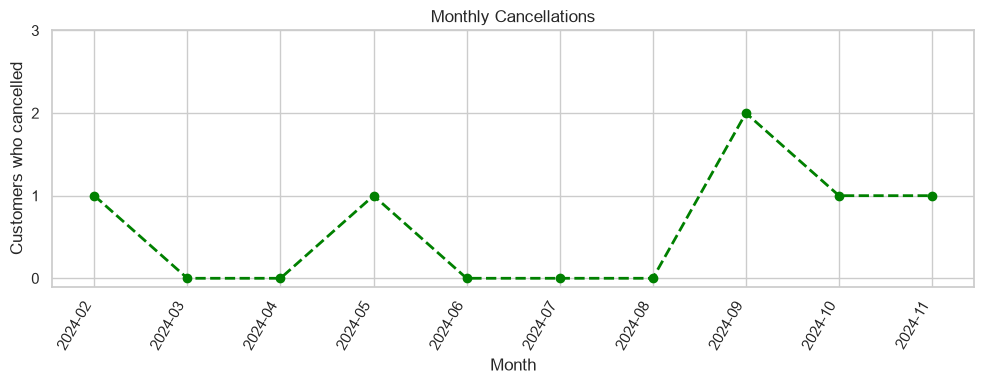

In [17]:
cancelled = df.loc[df['churn_flag'] == 1, 'cancellation_month']
all_months = pd.period_range(cancelled.min(), cancelled.max(), freq='M')
churn_trend = cancelled.value_counts().reindex(all_months, fill_value=0).sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(churn_trend.index.astype(str), churn_trend.values, marker='o', linestyle='--', color='green', linewidth=2)
ax.set_title('Monthly Cancellations')
ax.set_xlabel('Month')
ax.set_ylabel('Customers who cancelled')
ax.set_yticks(range(0, int(churn_trend.max()) + 2))
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

**Why this chart?** A line chart shows how a count changes over time. Months with no cancellations are filled with 0 so gaps show up as dips, not as missing points.

**Insight:** With only 6 cancellations in total, each month holds 0 to 2 cancellations, so the shape of the line is mostly noise.

**Business impact:** On a larger dataset this chart would reveal seasonality or the effect of a price change or a campaign. Here it only shows *when* these 6 customers left.

### Chart 5: Correlation heatmap

Correlations need numbers, so the text categories are converted with **ordered encoding**: codes follow the natural order (for example Basic < Standard < Premium), unlike alphabetical codes, which would invent a meaningless order and distort the correlations.

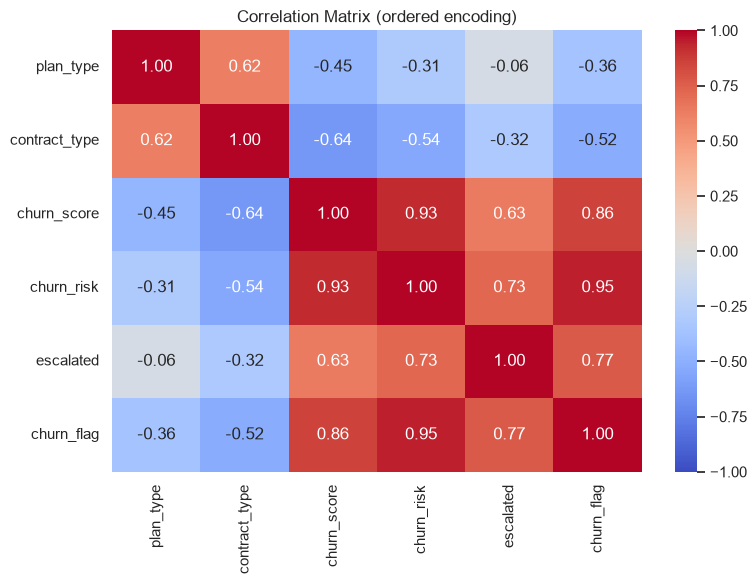

Escalation vs churn correlation: 0.77


In [18]:
order_mapping = {
    'plan_type':     ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk':    ['low', 'med', 'high'],
}

df_encoded = df[['plan_type', 'contract_type', 'churn_score', 'churn_risk', 'escalated', 'churn_flag']].copy()
for col, order in order_mapping.items():
    df_encoded[col] = pd.Categorical(df_encoded[col], categories=order, ordered=True).codes

corr = df_encoded.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Matrix (ordered encoding)')
plt.tight_layout()
plt.show()

print('Escalation vs churn correlation:', round(corr.loc['escalated', 'churn_flag'], 2))

**Why this chart?** A heatmap shows every pairwise relationship at once, which is useful for spotting which fields move with churn.

**Insight:** In the original run, escalations and churn correlated at **0.77**: customers whose latest complaint was escalated mostly churned. Note that `churn_score` is a pre-computed field in the source data, so a strong link between it and `churn_flag` is expected and is not independent evidence.

**Business impact:** An escalated complaint is an early warning signal, so routing escalated customers to a retention team is a sensible rule to test.

**Caution:** The 0.77 comes from 21 customers, of whom only 4 escalated. Correlation also does not show that escalation *causes* churn. It illustrates the method rather than proving the effect.

### Summary table: plan performance

In [19]:
plan_summary = pd.pivot_table(
    df,
    index='plan_type',
    values=['customerid', 'monthly_charges', 'churn_flag'],
    aggfunc={'customerid': 'nunique', 'monthly_charges': 'sum', 'churn_flag': 'mean'},
).reindex(plan_order)

plan_summary = plan_summary.rename(columns={
    'customerid': 'customers',
    'monthly_charges': 'total_monthly_charges',
    'churn_flag': 'churn_rate',
})
plan_summary['churn_rate'] = (plan_summary['churn_rate'] * 100).round(2)
plan_summary[['customers', 'total_monthly_charges', 'churn_rate']]

,customers,total_monthly_charges,churn_rate
plan_type,,,
Basic,5,52.95,60.00
Standard,9,123.91,22.22
Premium,7,218.93,14.29


A pivot table puts customers, revenue and churn side by side. In this dataset, Premium brings in the most monthly revenue and has the lowest churn, while Basic has the highest churn and the smallest revenue base.

## Conclusion

**Key findings** (from the run on the original data)

1. **Overall churn is 28.57%** (6 of 21 customers), so retention is 71.43%.
2. **Plan matters:** Basic churns at 60%, Standard at about 22% and Premium at about 14%.
3. **Acquisition channel matters:** Referral customers churned at about 83% against 0% for Organic and about 17% for Paid.
4. **Escalations track with churn:** correlation of 0.77 between an escalated complaint and churn.
5. **ARPU is 18.85** and the monthly charges of churned customers total 73.94 (currency unit not specified in the source).

**Recommendations to test on real data**

- Target retention offers and onboarding at Basic-plan customers.
- Review the referral programme and check which cancellation reasons dominate.
- Route escalated complaints to a retention team and track what happens next.
- Use the `churn_risk` segments to prioritize outreach to active, high-risk customers.

**Limitations**

- **Sample size:** 21 customers and 6 churn events. State-level and month-level results are especially unstable, and no result here is statistically tested.
- **Support history:** only the latest complaint per customer is kept, and customers with no complaint are treated as not escalated.
- **Provided score:** `churn_score` comes from the source data, so its link to churn is not an independent finding.
- **Date dependence:** average tenure for active customers moves with the date the notebook is run.